<a href="https://colab.research.google.com/github/Heshan-V/natural-language-processing/blob/main/LogisticRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%cd /content/drive/MyDrive/NLP/Code Notebooks

/content/drive/MyDrive/NLP/Code Notebooks


In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split #splitting the dataset
from sklearn.feature_extraction.text import TfidfVectorizer #vectorization using tfidf
from sklearn.linear_model import LogisticRegression #modal
from sklearn.pipeline import Pipeline #training pipeline
from sklearn.metrics import (accuracy_score,
confusion_matrix,classification_report, roc_auc_score)
# metrics for evaluation
# for plots
import numpy as np # for numerical analysis
import matplotlib.pyplot as plt #drawing the plots
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
#evaluation metrics

In [7]:
positive = [
"The acting was excellent", "A great story and wonderful music",
"I loved this movie", "What an amazing film",
"The story was brilliant and the acting was great", "I really enjoyed this film",
"Beautiful music and excellent acting", "An amazing and wonderful movie",
"I loved the story and the music", "A fantastic film with great actors",
"The ending was perfect", "I enjoyed every minute of this brilliant movie",
"Wonderful acting and a beautiful story", "This film is fantastic",
"A perfect movie for the weekend", "The actors were brilliant",
"Great music and an amazing ending", "I loved the actors, they were excellent",
"A beautiful and enjoyable film", "The plot was great and the ending was wonderful",
"Really fantastic acting", "An excellent story, I enjoyed it",
"The movie was perfect and beautiful", "Amazing actors and brilliant music",
"I enjoyed the film, it was great", "A wonderful plot and a fantastic cast",
"The music was excellent", "Brilliant, beautiful and perfect",
"I loved every minute of it", "Such an amazing story",
"Not boring at all, I loved it", "The actors were not bad, the story was great"]

negative = [
"The acting was terrible", "A boring story and awful music",
"I hated this movie", "What a disappointing film",
"The story was dull and the acting was bad", "I really disliked this film",
"Awful music and terrible acting", "A boring and disappointing movie",
"I hated the story and the music", "A poor film with bad actors",
"The ending was awful", "I wasted every minute on this dull movie",
"Terrible acting and a boring story", "This film is a waste of time",
"A bad movie for the weekend", "The actors were poor",
"Boring music and a terrible ending", "I hated the actors, they were awful",
"A dull and disappointing film", "The plot was bad and the ending was boring",
"Really terrible acting", "A poor story, I disliked it",
"The movie was boring and awful", "Bad actors and dull music",
"I disliked the film, it was terrible", "A disappointing plot and a poor cast",
"The music was awful", "Boring, dull and disappointing",
"I hated every minute of it", "Such a terrible story",
"The music was not great", "Not a good film, the plot was dull"]

In [9]:
df = pd.DataFrame({
"review": positive + negative, #join to one column
"label": [1] * len(positive) + [0] * len(negative)}) # makes matching lable coloumns 1 for positive, 0 for negative
print(df.shape) #get number of rows and columns
print(df["label"].value_counts()) #how many 1s nd 0s
print(df.head())

(64, 2)
label
1    32
0    32
Name: count, dtype: int64
                                             review  label
0                          The acting was excellent      1
1                 A great story and wonderful music      1
2                                I loved this movie      1
3                              What an amazing film      1
4  The story was brilliant and the acting was great      1


In [11]:
X = df["review"] # input: the text
y = df["label"] # target: the label
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.25, random_state=42, stratify=y) #train = 75% test 25%, stratify y => keeps the smae positive/ negative ration in both train and test set
print(len(X_train), len(X_test))
print(y_train.value_counts().to_dict())
print(y_test.value_counts().to_dict()) #checking train and test sets are balanced
print(X_test.tolist()[:3])

48 16
{1: 24, 0: 24}
{0: 8, 1: 8}
['I hated every minute of it', 'Not boring at all, I loved it', 'A boring and disappointing movie']


In [12]:
tfidf = TfidfVectorizer() #tfidf converter
X_train_vec = tfidf.fit_transform(X_train) # learns the vocab, each wordidf score, trasnsform to tf-idf vectors
print(X_train_vec.shape) # reviews, unique word matrix size
v = tfidf.transform(["I loved this movie"]) #convert new sentence
words = tfidf.get_feature_names_out() #get the list of words in the vocab
print({words[i]: round(float(v[0, i]), 3) for i in v.nonzero()[1]})

(48, 49)
{'loved': 0.628, 'movie': 0.563, 'this': 0.538}


In [14]:
model = Pipeline([
("tfidf", TfidfVectorizer()), #step 1 - turns text to tfidf
("classifier", LogisticRegression( #step 2 - learn the weights andmake predicitons
max_iter=1000, # optimisation steps
C=1.0 # regularization (default)
))
])

In [16]:
model.fit(X_train, y_train) # z - sigmoid - loss - regularization gradients - update weights - repeat until convergence

Pipeline(steps=[('tfidf', TfidfVectorizer()),
                ('classifier', LogisticRegression(max_iter=1000))])

In [17]:
clf = model.named_steps["classifier"] #get hte trained classifier
words = model.named_steps["tfidf"].get_feature_names_out()
w = clf.coef_[0] # one weight per word
order = w.argsort() # most negative ... most positive
print("negative:", [(words[i], float(round(w[i], 2))) for i in order[:5]])
print("positive:", [(words[i], float(round(w[i], 2))) for i in order[-5:]])
print("bias:", clf.intercept_.round(3))

negative: [('terrible', -0.91), ('boring', -0.76), ('dull', -0.75), ('awful', -0.74), ('poor', -0.7)]
positive: [('fantastic', 0.63), ('amazing', 0.66), ('wonderful', 0.75), ('loved', 0.78), ('excellent', 0.86)]
bias: [-0.047]


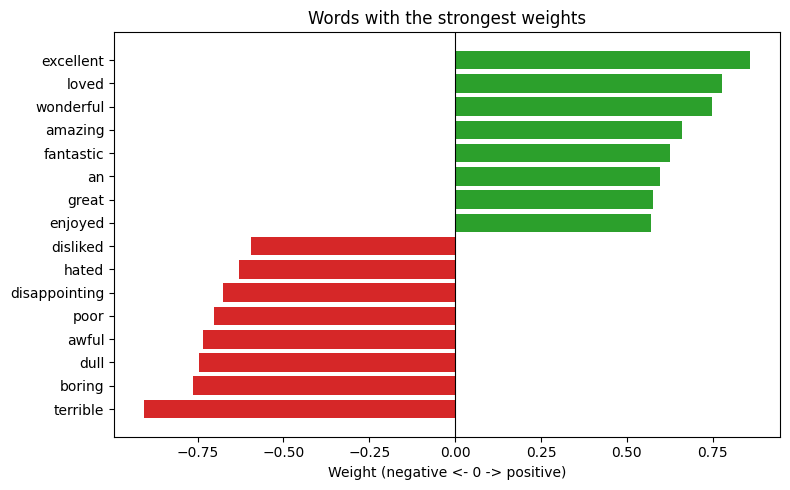

In [18]:
top = np.concatenate([order[:8], order[-8:]]) # 8 most negative + 8 most positive words
plt.figure(figsize=(8, 5))
plt.barh(words[top], w[top],
color=["tab:red" if w[i] < 0 else "tab:green" for i in top])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Words with the strongest weights")
plt.xlabel("Weight (negative <- 0 -> positive)")
plt.tight_layout()
plt.show()

In [19]:
y_pred = model.predict(X_test) # 0 / 1
y_prob = model.predict_proba(X_test) # P(0), P(1)
label_name = {0: "negative", 1: "positive"}
results = pd.DataFrame({
"review": X_test,
"true": y_test.map(label_name),
"pred": pd.Series(y_pred, index=X_test.index).map(label_name),
"P(pos)": y_prob[:, 1].round(2)})
results["correct"] = results["true"] == results["pred"]
print(results.sort_values("P(pos)").to_string(index=False)) # all 16, sorted

                                        review     true     pred  P(pos)  correct
              A boring and disappointing movie negative negative    0.30     True
               Awful music and terrible acting negative negative    0.31     True
            Not a good film, the plot was dull negative negative    0.41     True
                        Really terrible acting negative negative    0.43     True
                    I hated every minute of it negative negative    0.44     True
                          The ending was awful negative negative    0.45     True
                   A bad movie for the weekend negative negative    0.45     True
    The plot was bad and the ending was boring negative negative    0.47     True
                 Not boring at all, I loved it positive negative    0.49    False
                     The actors were brilliant positive positive    0.54     True
            A fantastic film with great actors positive positive    0.56     True
                

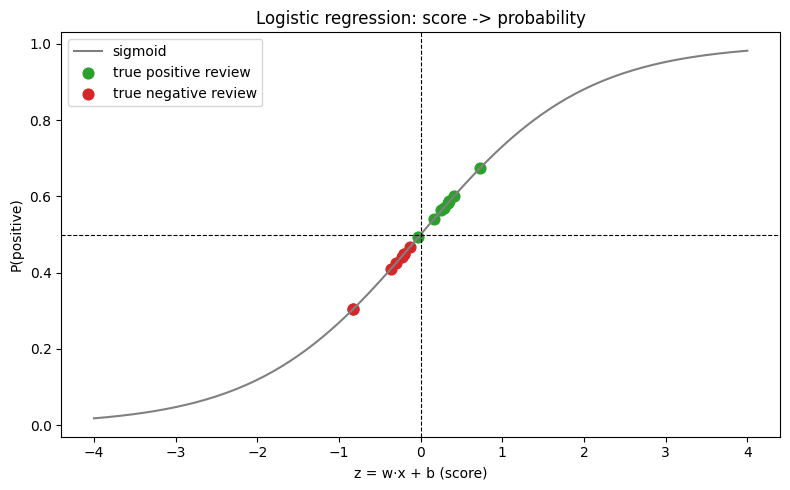

In [20]:
z = model.decision_function(X_test) # raw score z = w·x + b
zz = np.linspace(-4, 4, 200)
plt.figure(figsize=(8, 5))
plt.plot(zz, 1 / (1 + np.exp(-zz)), color="gray", label="sigmoid")
plt.scatter(z[y_test == 1], y_prob[y_test == 1, 1], color="tab:green",
s=60, label="true positive review")
plt.scatter(z[y_test == 0], y_prob[y_test == 0, 1], color="tab:red",
s=60, label="true negative review")
plt.axhline(0.5, linestyle="--", color="black", linewidth=0.8) # decision threshold
plt.axvline(0, linestyle="--", color="black", linewidth=0.8)
plt.xlabel("z = w·x + b (score)")
plt.ylabel("P(positive)")
plt.title("Logistic regression: score -> probability")
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred,
target_names=["negative", "positive"]))

Accuracy: 0.938
[[8 0]
 [1 7]]
              precision    recall  f1-score   support

    negative       0.89      1.00      0.94         8
    positive       1.00      0.88      0.93         8

    accuracy                           0.94        16
   macro avg       0.94      0.94      0.94        16
weighted avg       0.94      0.94      0.94        16



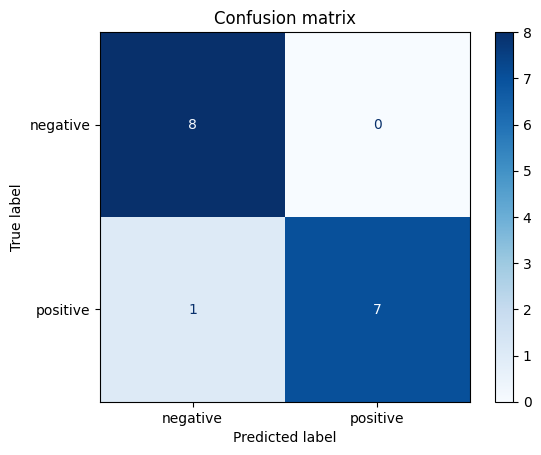

In [22]:
ConfusionMatrixDisplay.from_predictions(
y_test, y_pred, display_labels=["negative", "positive"], cmap="Blues")
plt.title("Confusion matrix")
plt.show()

In [23]:
auc = roc_auc_score(y_test, y_prob[:, 1])
print("ROC-AUC:", round(auc, 3))

ROC-AUC: 1.0


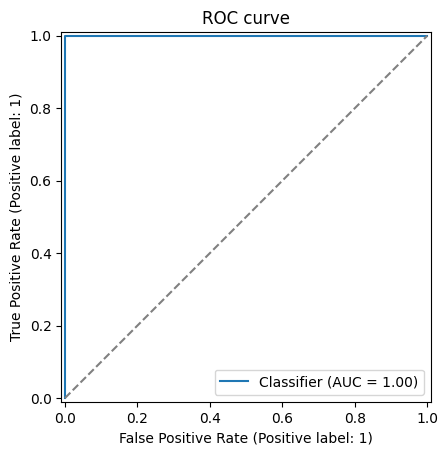

In [24]:
RocCurveDisplay.from_predictions(y_test, y_prob[:, 1])
plt.plot([0, 1], [0, 1], "--", color="gray") # random guess line
plt.title("ROC curve")
plt.show()

In [25]:
new_reviews = ["The story was wonderful and the actors were brilliant",
"I loved the music and the ending was perfect",
"A boring film, I hated the ending",
"The acting was terrible and the plot was dull",
"The movie was not good",
"The film was not bad at all"]
print(pd.DataFrame({
"review": new_reviews,
"prediction": [label_name[i] for i in model.predict(new_reviews)],
"P(pos)": model.predict_proba(new_reviews)[:,
1].round(3)}).to_string(index=False))

                                               review prediction  P(pos)
The story was wonderful and the actors were brilliant   positive   0.612
         I loved the music and the ending was perfect   positive   0.667
                    A boring film, I hated the ending   negative   0.346
        The acting was terrible and the plot was dull   negative   0.409
                               The movie was not good   negative   0.494
                          The film was not bad at all   negative   0.432
